In [1]:
!pip install folium
!pip install geopandas
!pip install scikit-learn
!pip install scipy

print("If packages are not installed, uncomment the pip install lines above")


   -------------------------- ------------- 2/3 [folium]
   ---------------------------------------- 3/3 [folium]

   ---------------------------------------- 0.0/22.9 MB ? eta -:--:--
   --------------------- ------------------ 12.6/22.9 MB 64.9 MB/s eta 0:00:01
   ------------------------------- -------- 17.8/22.9 MB 54.1 MB/s eta 0:00:01
   ---------------------------------------- 22.9/22.9 MB 45.1 MB/s  0:00:00
   ---------------------------------------- 0.0/6.3 MB ? eta -:--:--
   --------------------------------- ------ 5.2/6.3 MB 24.7 MB/s eta 0:00:01
   ---------------------------------------- 6.3/6.3 MB 25.9 MB/s  0:00:00
   ---------------------------------------- 0.0/1.7 MB ? eta -:--:--
   ---------------------------------------- 1.7/1.7 MB 33.2 MB/s  0:00:00

   ---------------------------------------- 0/4 [shapely]
   ---------------------------------------- 0/4 [shapely]
   ---------------------------------------- 0/4 [shapely]
   ---------- ----------------------------

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import folium
from folium.plugins import HeatMap, MarkerCluster
from sklearn.cluster import DBSCAN, KMeans
from scipy.spatial import ConvexHull
from scipy.spatial.distance import cdist
import warnings

warnings.filterwarnings('ignore')

# Set style
sns.set_style("whitegrid")
plt.rcParams['figure.figsize'] = (14, 8)

print("✓ All libraries imported successfully!")

✓ All libraries imported successfully!


In [3]:
# Load the cleaned data (or original if you haven't cleaned yet)
try:
    df = pd.read_csv('the_hague_restaurants_cleaned.csv')
    print("✓ Loaded cleaned data")
except:
    df = pd.read_csv('the_hague_restaurants.csv')
    df = df[df['rating'].notna()]  # Remove rows without ratings
    print("✓ Loaded original data and filtered")

print(f"\nDataset: {len(df)} restaurants")
print(f"Coordinate range:")
print(f"  Latitude:  {df['latitude'].min():.4f} to {df['latitude'].max():.4f}")
print(f"  Longitude: {df['longitude'].min():.4f} to {df['longitude'].max():.4f}")

# Show sample
df.head()

✓ Loaded cleaned data

Dataset: 60 restaurants
Coordinate range:
  Latitude:  52.0371 to 52.1144
  Longitude: 4.2552 to 4.3696


,place_id,name,address,latitude,longitude,rating,user_ratings_total,price_level,types,business_status,full_address,phone,website,open_now,collected_date,price_category,popularity_score
0,ChIJXWizKLewxUcRZkf-eWhK5_U,Leonardo Royal Hotel Den Haag Promenade,"Van Stolkweg 1, Den Haag",52.097001,4.287193,4.4,2864,NaN,"gym, lodging, spa, restaurant, food, health, p...",OPERATIONAL,"Van Stolkweg 1, 2585 JL Den Haag, Netherlands",070 352 5161,https://www.leonardo-hotels.com/the-hague/leon...,True,2025-12-08 18:17:52,Unknown,35.025424
1,ChIJz01uUDG3xUcRG3sPVyCL_Is,Carlton Ambassador,"Sophialaan 2, Den Haag",52.085669,4.302694,4.4,931,NaN,"lodging, restaurant, food, point_of_interest, ...",OPERATIONAL,"Sophialaan 2, 2514 JP Den Haag, Netherlands",070 363 0363,https://www.carltonambassador.nl/,True,2025-12-08 18:17:52,Unknown,30.084264
2,ChIJr0n5mDu3xUcRQA8VOP4EbAE,Hotel Des Indes,"Lange Voorhout 54-56, Den Haag",52.083780,4.313129,4.5,1811,NaN,"lodging, spa, restaurant, food, point_of_inter...",OPERATIONAL,"Lange Voorhout 54-56, 2514 EG Den Haag, Nether...",070 361 2345,https://www.hoteldesindesthehague.com/,True,2025-12-08 18:17:52,Unknown,33.759839
3,ChIJIw6-NyK3xUcRN2eDfx9PR18,Mercure Hotel Den Haag Central,"Spui 180, Den Haag",52.076498,4.318043,4.3,1932,NaN,"lodging, restaurant, food, point_of_interest, ...",OPERATIONAL,"Spui 180, 2511 BW Den Haag, Netherlands",070 203 9002,https://all.accor.com/lien_externe.svlt?goto=f...,NaN,2025-12-08 18:17:52,Unknown,32.537362
4,ChIJs8vdpxe3xUcRDIeT8asAD0o,Leonardo Hotel Den Haag Babylon,"Bezuidenhoutseweg 53, Den Haag",52.082600,4.324418,4.3,1583,NaN,"lodging, restaurant, food, point_of_interest, ...",OPERATIONAL,"Bezuidenhoutseweg 53, 2595 AA Den Haag, Nether...",070 381 4901,https://www.leonardo-hotels.nl/the-hague/leona...,NaN,2025-12-08 18:17:52,Unknown,31.681147


In [4]:
print("CREATING BASIC SPATIAL MAP")
print("="*60)

# Create base map centered on The Hague
center_lat = df['latitude'].mean()
center_lon = df['longitude'].mean()

m = folium.Map(
    location=[center_lat, center_lon],
    zoom_start=12,
    tiles='OpenStreetMap'
)

# Add all restaurants as markers (colored by rating)
def get_color(rating):
    if rating >= 4.5:
        return 'green'
    elif rating >= 4.0:
        return 'lightgreen'
    elif rating >= 3.5:
        return 'orange'
    else:
        return 'red'

for idx, row in df.iterrows():
    folium.CircleMarker(
        location=[row['latitude'], row['longitude']],
        radius=5,
        popup=f"<b>{row['name']}</b><br>Rating: {row['rating']}<br>Reviews: {row['user_ratings_total']}",
        color=get_color(row['rating']),
        fill=True,
        fillColor=get_color(row['rating']),
        fillOpacity=0.7
    ).add_to(m)

# Save map
m.save('the_hague_restaurants_map.html')
print("✓ Basic map saved: the_hague_restaurants_map.html")
print("  Open this file in your browser to explore interactively")

CREATING BASIC SPATIAL MAP
✓ Basic map saved: the_hague_restaurants_map.html
  Open this file in your browser to explore interactively


In [5]:
print("CREATING DENSITY HEATMAP")
print("="*60)

# Create heatmap
m_heat = folium.Map(
    location=[center_lat, center_lon],
    zoom_start=12,
    tiles='OpenStreetMap'
)

# Prepare data for heatmap
heat_data = [[row['latitude'], row['longitude']] for idx, row in df.iterrows()]

# Add heatmap layer
HeatMap(
    heat_data,
    radius=15,
    blur=25,
    max_zoom=13,
    gradient={0.4: 'blue', 0.6: 'lime', 0.8: 'orange', 1.0: 'red'}
).add_to(m_heat)

# Save heatmap
m_heat.save('the_hague_density_heatmap.html')
print("✓ Density heatmap saved: the_hague_density_heatmap.html")
print("  Red areas = high density, Blue areas = low density")

CREATING DENSITY HEATMAP
✓ Density heatmap saved: the_hague_density_heatmap.html
  Red areas = high density, Blue areas = low density


DBSCAN CLUSTERING ANALYSIS

✓ Clustering complete!
  Number of clusters found: 2
  Restaurants in clusters: 45
  Isolated restaurants (noise): 15

Cluster sizes:
  Cluster 0: 45 restaurants


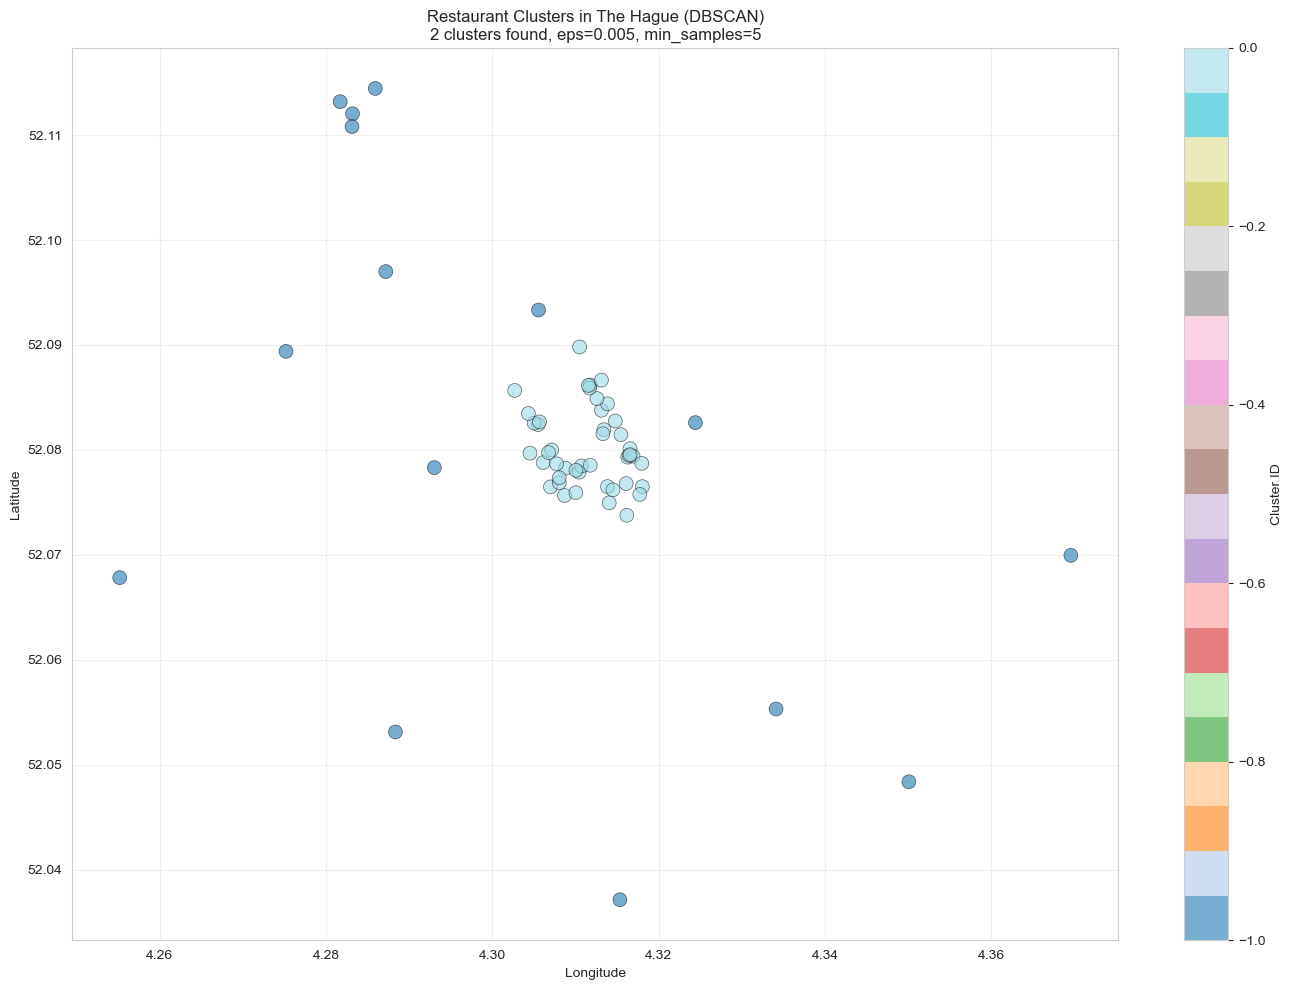


✓ Cluster visualization saved: cluster_map.png


In [6]:
print("DBSCAN CLUSTERING ANALYSIS")
print("="*60)

# Prepare coordinates for clustering
# Note: We need to scale coordinates properly for distance calculation
# Using approximate conversion: 1 degree ≈ 111km at this latitude
coords = df[['latitude', 'longitude']].values

# DBSCAN parameters
# eps = 0.005 means approximately 500m radius
# min_samples = 5 means at least 5 restaurants to form a cluster
eps_distance = 0.005  # approximately 500 meters
min_samples = 5

dbscan = DBSCAN(eps=eps_distance, min_samples=min_samples)
df['cluster'] = dbscan.fit_predict(coords)

# Cluster statistics
n_clusters = len(set(df['cluster'])) - (1 if -1 in df['cluster'] else 0)
n_noise = list(df['cluster']).count(-1)

print(f"\n✓ Clustering complete!")
print(f"  Number of clusters found: {n_clusters}")
print(f"  Restaurants in clusters: {len(df) - n_noise}")
print(f"  Isolated restaurants (noise): {n_noise}")

# Cluster sizes
cluster_sizes = df[df['cluster'] != -1]['cluster'].value_counts().sort_index()
print(f"\nCluster sizes:")
for cluster_id, size in cluster_sizes.items():
    print(f"  Cluster {cluster_id}: {size} restaurants")

# Visualize clusters
plt.figure(figsize=(14, 10))
scatter = plt.scatter(
    df['longitude'], 
    df['latitude'], 
    c=df['cluster'], 
    cmap='tab20',
    s=100,
    alpha=0.6,
    edgecolors='black',
    linewidth=0.5
)
plt.xlabel('Longitude')
plt.ylabel('Latitude')
plt.title(f'Restaurant Clusters in The Hague (DBSCAN)\n{n_clusters} clusters found, eps={eps_distance}, min_samples={min_samples}')
plt.colorbar(scatter, label='Cluster ID')
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig('cluster_map.png', dpi=300, bbox_inches='tight')
plt.show()

print("\n✓ Cluster visualization saved: cluster_map.png")

In [7]:
print("CREATING INTERACTIVE CLUSTER MAP")
print("="*60)

# Create map with clusters
m_cluster = folium.Map(
    location=[center_lat, center_lon],
    zoom_start=12,
    tiles='OpenStreetMap'
)

# Color palette for clusters
colors = ['red', 'blue', 'green', 'purple', 'orange', 'darkred', 
          'lightred', 'beige', 'darkblue', 'darkgreen', 'cadetblue', 
          'darkpurple', 'white', 'pink', 'lightblue', 'lightgreen', 
          'gray', 'black', 'lightgray']

# Add markers for each cluster
for cluster_id in sorted(df['cluster'].unique()):
    if cluster_id == -1:
        # Noise points in gray
        cluster_data = df[df['cluster'] == cluster_id]
        for idx, row in cluster_data.iterrows():
            folium.CircleMarker(
                location=[row['latitude'], row['longitude']],
                radius=4,
                popup=f"<b>{row['name']}</b><br>Isolated<br>Rating: {row['rating']}",
                color='gray',
                fill=True,
                fillColor='gray',
                fillOpacity=0.4
            ).add_to(m_cluster)
    else:
        # Cluster points
        cluster_data = df[df['cluster'] == cluster_id]
        color = colors[cluster_id % len(colors)]
        
        # Calculate cluster center
        cluster_center = [
            cluster_data['latitude'].mean(),
            cluster_data['longitude'].mean()
        ]
        
        # Add cluster circle
        folium.Circle(
            location=cluster_center,
            radius=600,  # 600 meters
            popup=f"<b>Cluster {cluster_id}</b><br>{len(cluster_data)} restaurants<br>Avg rating: {cluster_data['rating'].mean():.2f}",
            color=color,
            fill=True,
            fillColor=color,
            fillOpacity=0.2
        ).add_to(m_cluster)
        
        # Add markers
        for idx, row in cluster_data.iterrows():
            folium.CircleMarker(
                location=[row['latitude'], row['longitude']],
                radius=5,
                popup=f"<b>{row['name']}</b><br>Cluster {cluster_id}<br>Rating: {row['rating']}<br>Reviews: {row['user_ratings_total']}",
                color=color,
                fill=True,
                fillColor=color,
                fillOpacity=0.8
            ).add_to(m_cluster)

# Save cluster map
m_cluster.save('the_hague_clusters_interactive.html')
print("✓ Interactive cluster map saved: the_hague_clusters_interactive.html")

CREATING INTERACTIVE CLUSTER MAP
✓ Interactive cluster map saved: the_hague_clusters_interactive.html


CLUSTER QUALITY ANALYSIS

Cluster Analysis Summary:
 cluster_id  restaurant_count  avg_rating  median_rating  avg_reviews  total_reviews  high_rated_count  competition_intensity  center_lat  center_lon
          0                45    4.291111            4.3  1335.333333          60090                15              88.888889   52.080213    4.311456


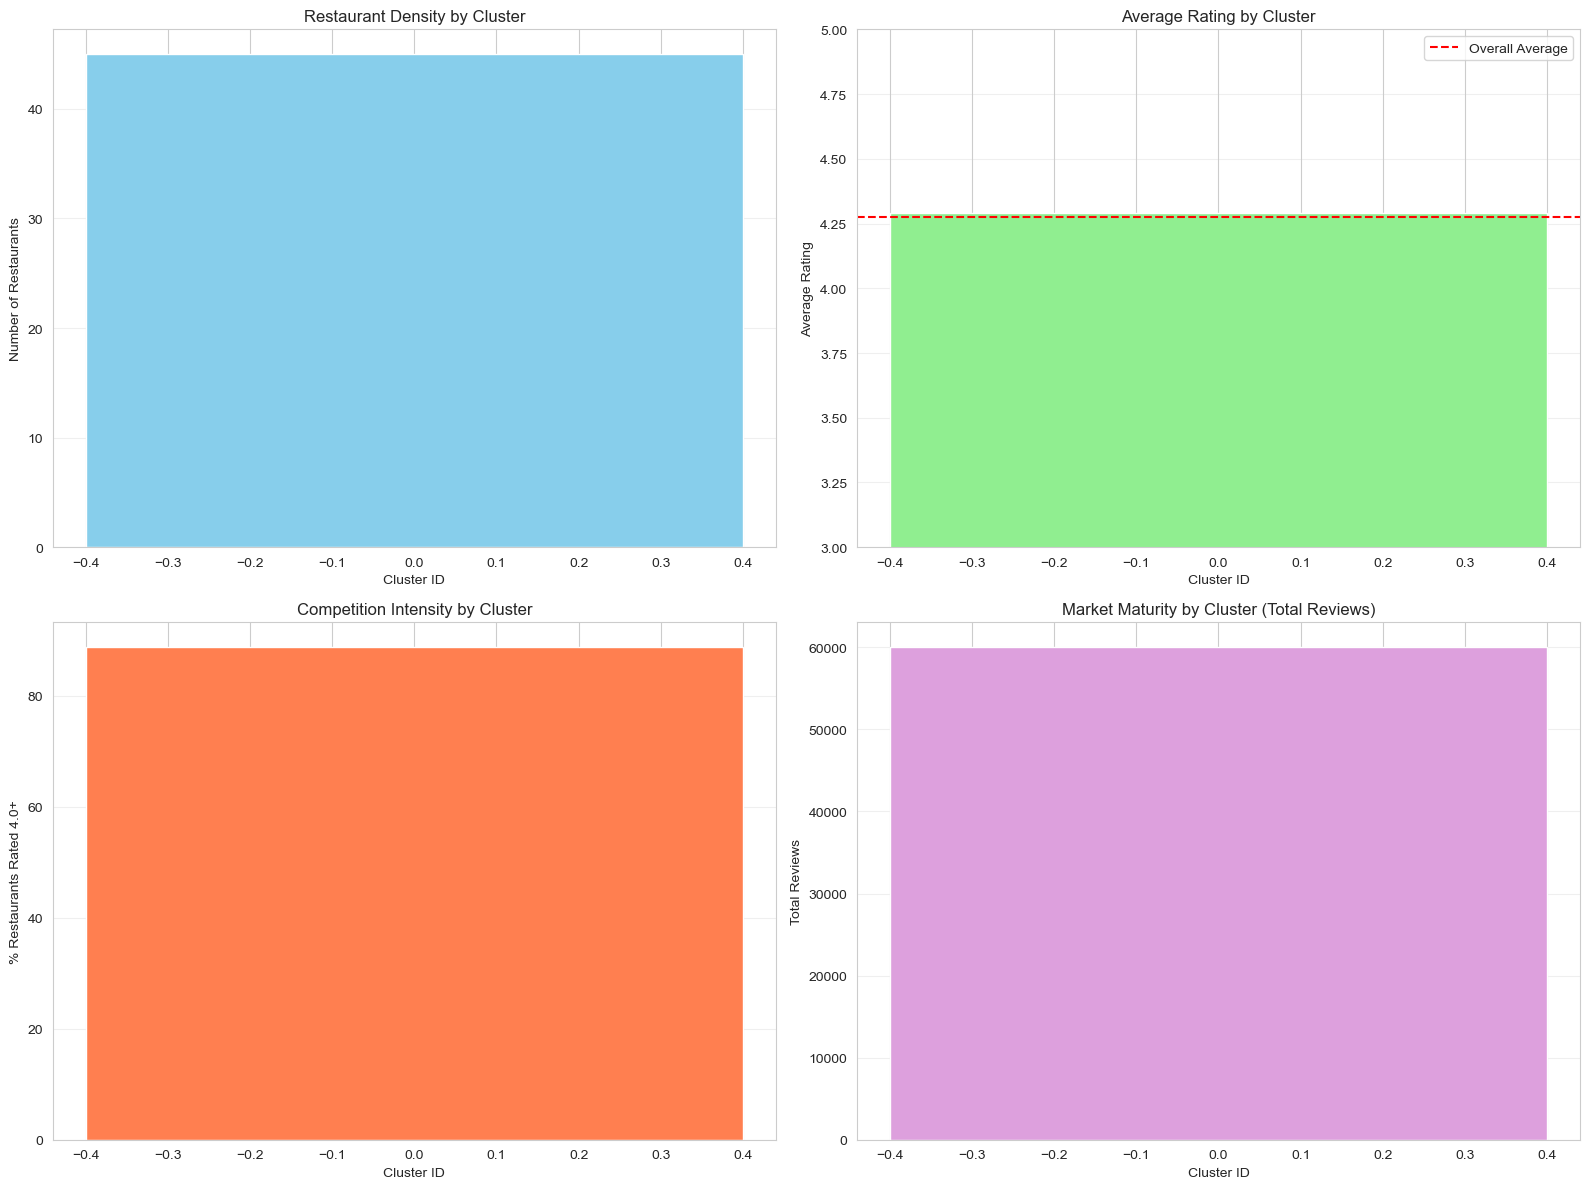


✓ Cluster analysis visualization saved: cluster_analysis.png


In [8]:
print("CLUSTER QUALITY ANALYSIS")
print("="*60)

# Analyze each cluster
cluster_analysis = []

for cluster_id in sorted(df[df['cluster'] != -1]['cluster'].unique()):
    cluster_data = df[df['cluster'] == cluster_id]
    
    analysis = {
        'cluster_id': cluster_id,
        'restaurant_count': len(cluster_data),
        'avg_rating': cluster_data['rating'].mean(),
        'median_rating': cluster_data['rating'].median(),
        'avg_reviews': cluster_data['user_ratings_total'].mean(),
        'total_reviews': cluster_data['user_ratings_total'].sum(),
        'high_rated_count': len(cluster_data[cluster_data['rating'] >= 4.5]),
        'competition_intensity': len(cluster_data[cluster_data['rating'] >= 4.0]) / len(cluster_data) * 100,
        'center_lat': cluster_data['latitude'].mean(),
        'center_lon': cluster_data['longitude'].mean()
    }
    
    cluster_analysis.append(analysis)

cluster_df = pd.DataFrame(cluster_analysis)

print(f"\nCluster Analysis Summary:")
print("="*60)
print(cluster_df.to_string(index=False))

# Visualize cluster metrics
fig, axes = plt.subplots(2, 2, figsize=(16, 12))

# Restaurant count per cluster
axes[0, 0].bar(cluster_df['cluster_id'], cluster_df['restaurant_count'], color='skyblue')
axes[0, 0].set_xlabel('Cluster ID')
axes[0, 0].set_ylabel('Number of Restaurants')
axes[0, 0].set_title('Restaurant Density by Cluster')
axes[0, 0].grid(axis='y', alpha=0.3)

# Average rating per cluster
axes[0, 1].bar(cluster_df['cluster_id'], cluster_df['avg_rating'], color='lightgreen')
axes[0, 1].axhline(y=df['rating'].mean(), color='red', linestyle='--', label='Overall Average')
axes[0, 1].set_xlabel('Cluster ID')
axes[0, 1].set_ylabel('Average Rating')
axes[0, 1].set_title('Average Rating by Cluster')
axes[0, 1].set_ylim([3, 5])
axes[0, 1].legend()
axes[0, 1].grid(axis='y', alpha=0.3)

# Competition intensity
axes[1, 0].bar(cluster_df['cluster_id'], cluster_df['competition_intensity'], color='coral')
axes[1, 0].set_xlabel('Cluster ID')
axes[1, 0].set_ylabel('% Restaurants Rated 4.0+')
axes[1, 0].set_title('Competition Intensity by Cluster')
axes[1, 0].grid(axis='y', alpha=0.3)

# Total reviews (market maturity)
axes[1, 1].bar(cluster_df['cluster_id'], cluster_df['total_reviews'], color='plum')
axes[1, 1].set_xlabel('Cluster ID')
axes[1, 1].set_ylabel('Total Reviews')
axes[1, 1].set_title('Market Maturity by Cluster (Total Reviews)')
axes[1, 1].grid(axis='y', alpha=0.3)

plt.tight_layout()
plt.savefig('cluster_analysis.png', dpi=300, bbox_inches='tight')
plt.show()

print("\n✓ Cluster analysis visualization saved: cluster_analysis.png")

NEAREST COMPETITOR ANALYSIS

Nearest Competitor Statistics:
  Mean distance: 461 meters
  Median distance: 128 meters
  Min distance: 15 meters
  Max distance: 3264 meters

Restaurants with competitor within 100m: 24
Isolated restaurants (>500m to competitor): 11


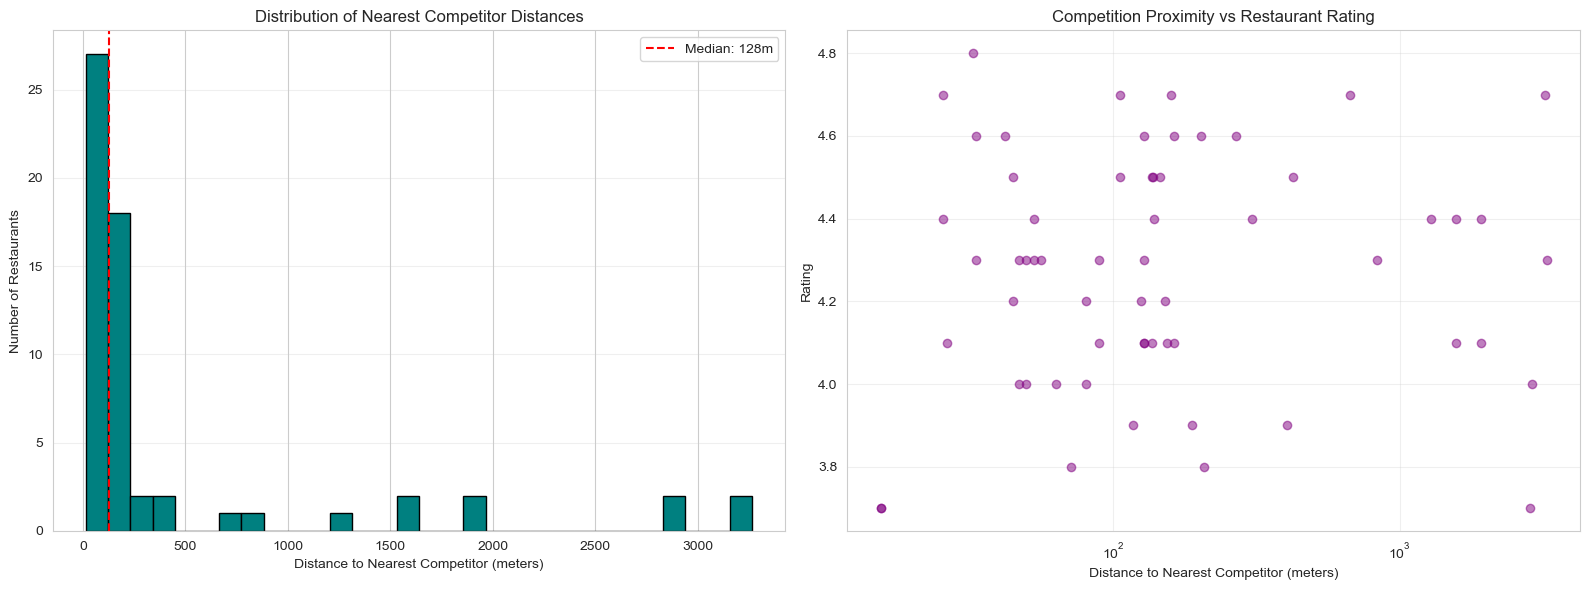


✓ Competitor analysis visualization saved: competitor_analysis.png


In [9]:
print("NEAREST COMPETITOR ANALYSIS")
print("="*60)

# Calculate distance to nearest competitor for each restaurant
coords = df[['latitude', 'longitude']].values

# Calculate pairwise distances (in degrees, approximately)
distances = cdist(coords, coords, metric='euclidean')

# Set diagonal to infinity to exclude self
np.fill_diagonal(distances, np.inf)

# Find nearest neighbor distance for each restaurant
df['nearest_competitor_distance'] = distances.min(axis=1)

# Convert to approximate meters (rough estimate)
# At this latitude, 1 degree ≈ 111km
df['nearest_competitor_meters'] = df['nearest_competitor_distance'] * 111000

print(f"\nNearest Competitor Statistics:")
print(f"  Mean distance: {df['nearest_competitor_meters'].mean():.0f} meters")
print(f"  Median distance: {df['nearest_competitor_meters'].median():.0f} meters")
print(f"  Min distance: {df['nearest_competitor_meters'].min():.0f} meters")
print(f"  Max distance: {df['nearest_competitor_meters'].max():.0f} meters")

# Find restaurants in highly competitive areas (nearest competitor < 100m)
highly_competitive = df[df['nearest_competitor_meters'] < 100]
print(f"\nRestaurants with competitor within 100m: {len(highly_competitive)}")

# Find isolated restaurants (nearest competitor > 500m)
isolated = df[df['nearest_competitor_meters'] > 500]
print(f"Isolated restaurants (>500m to competitor): {len(isolated)}")

# Visualize
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Distribution of distances
axes[0].hist(df['nearest_competitor_meters'], bins=30, color='teal', edgecolor='black')
axes[0].set_xlabel('Distance to Nearest Competitor (meters)')
axes[0].set_ylabel('Number of Restaurants')
axes[0].set_title('Distribution of Nearest Competitor Distances')
axes[0].axvline(x=df['nearest_competitor_meters'].median(), color='red', 
                linestyle='--', label=f'Median: {df["nearest_competitor_meters"].median():.0f}m')
axes[0].legend()
axes[0].grid(axis='y', alpha=0.3)

# Distance vs Rating
axes[1].scatter(df['nearest_competitor_meters'], df['rating'], alpha=0.5, color='purple')
axes[1].set_xlabel('Distance to Nearest Competitor (meters)')
axes[1].set_ylabel('Rating')
axes[1].set_title('Competition Proximity vs Restaurant Rating')
axes[1].set_xscale('log')
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig('competitor_analysis.png', dpi=300, bbox_inches='tight')
plt.show()

print("\n✓ Competitor analysis visualization saved: competitor_analysis.png")


MARKET OPPORTUNITY ANALYSIS

Grid Analysis (500m x 500m cells):
  Total grid cells: 368
  Cells with restaurants: 25
  Underserved cells (≤2 restaurants): 360


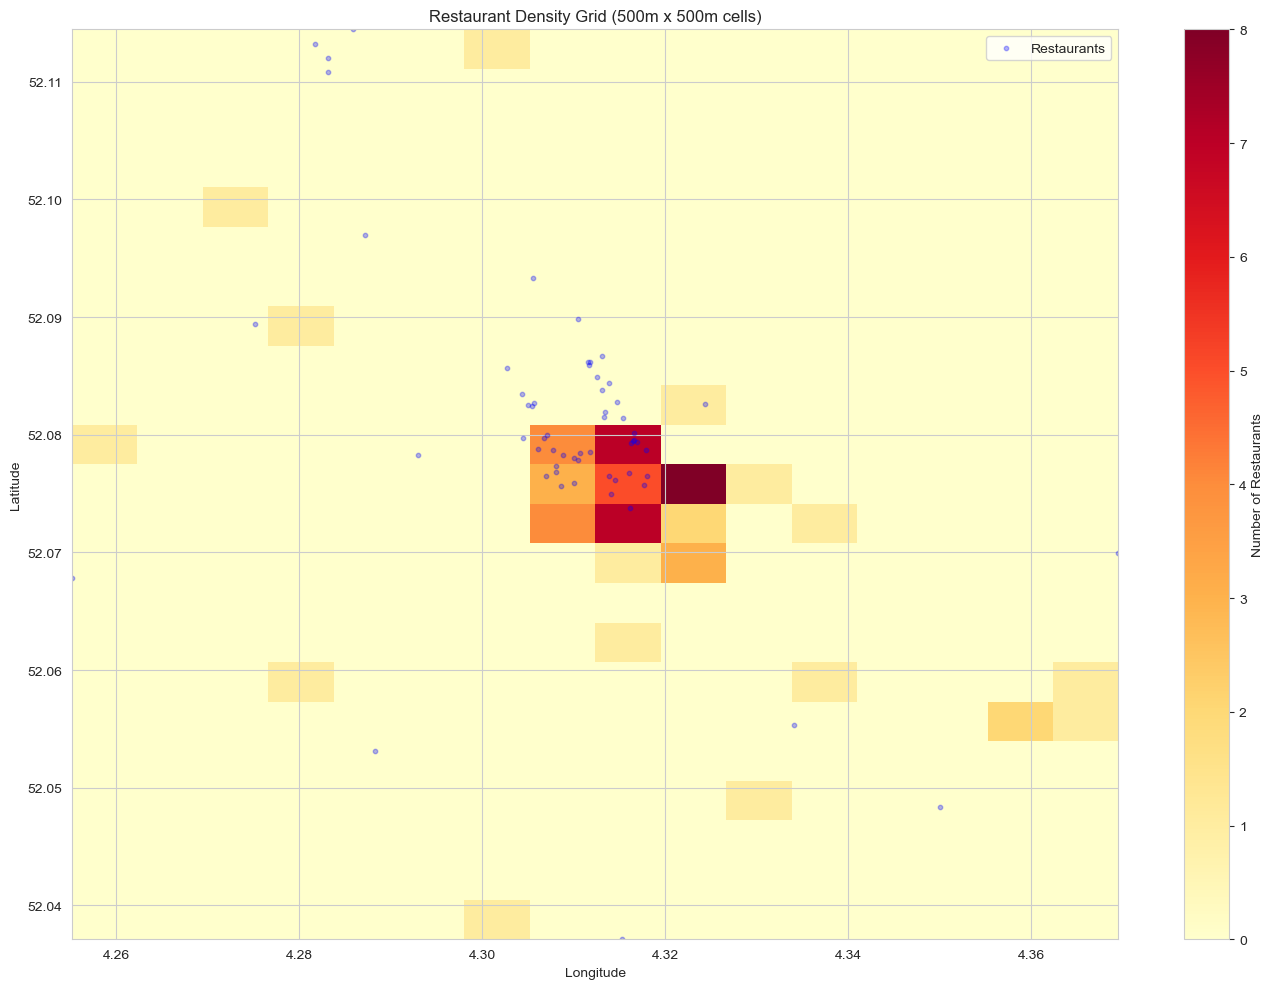


✓ Density grid visualization saved: density_grid.png


In [10]:
print("MARKET OPPORTUNITY ANALYSIS")
print("="*60)

# Create a grid over The Hague to find underserved areas
lat_min, lat_max = df['latitude'].min(), df['latitude'].max()
lon_min, lon_max = df['longitude'].min(), df['longitude'].max()

# Create grid (approximately 500m x 500m cells)
grid_size = 0.005  # approximately 500m
lat_bins = np.arange(lat_min, lat_max, grid_size)
lon_bins = np.arange(lon_min, lon_max, grid_size)

# Count restaurants in each grid cell
grid_counts = np.zeros((len(lat_bins), len(lon_bins)))

for _, row in df.iterrows():
    lat_idx = int((row['latitude'] - lat_min) / grid_size)
    lon_idx = int((row['longitude'] - lon_min) / grid_size)
    
    if lat_idx < len(lat_bins) and lon_idx < len(lon_bins):
        grid_counts[lat_idx, lon_idx] += 1

# Find underserved areas (low density cells)
underserved_threshold = 2
underserved_zones = []

for i, lat in enumerate(lat_bins):
    for j, lon in enumerate(lon_bins):
        if grid_counts[i, j] <= underserved_threshold:
            underserved_zones.append({
                'lat': lat + grid_size/2,
                'lon': lon + grid_size/2,
                'restaurant_count': grid_counts[i, j]
            })

print(f"\nGrid Analysis (500m x 500m cells):")
print(f"  Total grid cells: {len(lat_bins) * len(lon_bins)}")
print(f"  Cells with restaurants: {np.sum(grid_counts > 0)}")
print(f"  Underserved cells (≤{underserved_threshold} restaurants): {len(underserved_zones)}")

# Visualize grid density
plt.figure(figsize=(14, 10))
plt.imshow(grid_counts.T, origin='lower', cmap='YlOrRd', aspect='auto',
           extent=[lon_min, lon_max, lat_min, lat_max])
plt.colorbar(label='Number of Restaurants')
plt.scatter(df['longitude'], df['latitude'], c='blue', s=10, alpha=0.3, label='Restaurants')
plt.xlabel('Longitude')
plt.ylabel('Latitude')
plt.title('Restaurant Density Grid (500m x 500m cells)')
plt.legend()
plt.tight_layout()
plt.savefig('density_grid.png', dpi=300, bbox_inches='tight')
plt.show()

print("\n✓ Density grid visualization saved: density_grid.png")

In [11]:
print("CREATING OPPORTUNITY MAP")
print("="*60)

# Create opportunity map showing:
# - Green zones: Low competition, potential opportunity
# - Red zones: High competition, saturated market

m_opportunity = folium.Map(
    location=[center_lat, center_lon],
    zoom_start=12,
    tiles='OpenStreetMap'
)

# Add existing restaurants as small markers
for idx, row in df.iterrows():
    folium.CircleMarker(
        location=[row['latitude'], row['longitude']],
        radius=3,
        color='gray',
        fill=True,
        fillColor='gray',
        fillOpacity=0.5,
        popup=f"{row['name']}"
    ).add_to(m_opportunity)

# Add opportunity zones (green = opportunity, red = saturated)
for cluster_id, cluster_info in cluster_df.iterrows():
    # Determine if it's an opportunity or saturated
    if cluster_info['competition_intensity'] < 50:  # Less than 50% are highly rated
        color = 'green'
        opportunity = 'OPPORTUNITY'
    elif cluster_info['competition_intensity'] > 70:
        color = 'red'
        opportunity = 'SATURATED'
    else:
        color = 'orange'
        opportunity = 'MODERATE'
    
    folium.Circle(
        location=[cluster_info['center_lat'], cluster_info['center_lon']],
        radius=600,
        popup=f"""
        <b>Cluster {cluster_info['cluster_id']}</b><br>
        Status: {opportunity}<br>
        Restaurants: {cluster_info['restaurant_count']}<br>
        Avg Rating: {cluster_info['avg_rating']:.2f}<br>
        Competition: {cluster_info['competition_intensity']:.1f}%
        """,
        color=color,
        fill=True,
        fillColor=color,
        fillOpacity=0.3,
        weight=2
    ).add_to(m_opportunity)

# Add legend
legend_html = '''
<div style="position: fixed; 
            bottom: 50px; right: 50px; width: 200px; height: 140px; 
            background-color: white; border:2px solid grey; z-index:9999; 
            font-size:14px; padding: 10px">
<p><b>Market Opportunity Zones</b></p>
<p><span style="color:green;">●</span> Opportunity (Low competition)</p>
<p><span style="color:orange;">●</span> Moderate competition</p>
<p><span style="color:red;">●</span> Saturated (High competition)</p>
<p><span style="color:gray;">●</span> Existing restaurants</p>
</div>
'''
m_opportunity.get_root().html.add_child(folium.Element(legend_html))

m_opportunity.save('the_hague_opportunity_map.html')
print("✓ Opportunity map saved: the_hague_opportunity_map.html")

CREATING OPPORTUNITY MAP
✓ Opportunity map saved: the_hague_opportunity_map.html


In [12]:
print("STRATEGIC MARKET RECOMMENDATIONS")
print("="*60)

# Identify best opportunity clusters
opportunity_clusters = cluster_df[cluster_df['competition_intensity'] < 60].sort_values('restaurant_count')

print("\n1. MARKET ENTRY OPPORTUNITIES")
print("-" * 60)
print("\nClusters with Lower Competition:")
for idx, cluster in opportunity_clusters.head(5).iterrows():
    print(f"\nCluster {cluster['cluster_id']}:")
    print(f"  Location: ({cluster['center_lat']:.4f}, {cluster['center_lon']:.4f})")
    print(f"  Restaurants: {cluster['restaurant_count']}")
    print(f"  Average rating: {cluster['avg_rating']:.2f}")
    print(f"  Competition intensity: {cluster['competition_intensity']:.1f}%")
    print(f"  → Recommendation: {'STRONG OPPORTUNITY' if cluster['competition_intensity'] < 50 else 'MODERATE OPPORTUNITY'}")

# Identify saturated markets
saturated_clusters = cluster_df[cluster_df['competition_intensity'] > 70].sort_values('competition_intensity', ascending=False)

print("\n2. SATURATED MARKETS (HIGH COMPETITION)")
print("-" * 60)
for idx, cluster in saturated_clusters.head(3).iterrows():
    print(f"\nCluster {cluster['cluster_id']}:")
    print(f"  Restaurants: {cluster['restaurant_count']}")
    print(f"  Average rating: {cluster['avg_rating']:.2f}")
    print(f"  Competition intensity: {cluster['competition_intensity']:.1f}%")
    print(f"  → High-quality competition, difficult market entry")

# Market gaps
print("\n3. ISOLATED AREAS (POTENTIAL UNTAPPED MARKETS)")
print("-" * 60)
print(f"\nFound {len(isolated)} restaurants in isolated locations:")
for idx, row in isolated.head(5).iterrows():
    print(f"\n{row['name']}:")
    print(f"  Distance to nearest competitor: {row['nearest_competitor_meters']:.0f}m")
    print(f"  Rating: {row['rating']}")
    print(f"  → Nearby area may have demand but low supply")

print("\n4. KEY INSIGHTS")
print("-" * 60)
print(f"✓ Total clusters identified: {n_clusters}")
print(f"✓ Average cluster size: {cluster_df['restaurant_count'].mean():.1f} restaurants")
print(f"✓ Highest competition cluster: {cluster_df.loc[cluster_df['competition_intensity'].idxmax(), 'cluster_id']}")
print(f"✓ Best opportunity cluster: {opportunity_clusters.iloc[0]['cluster_id']}")
print(f"✓ {len(isolated)} isolated restaurants suggest underserved neighborhoods")

print("\n" + "="*60)
print("Spatial analysis complete!")
print("\nGenerated files:")
print("  - the_hague_restaurants_map.html")
print("  - the_hague_density_heatmap.html")
print("  - the_hague_clusters_interactive.html")
print("  - the_hague_opportunity_map.html")
print("  - cluster_map.png")
print("  - cluster_analysis.png")
print("  - competitor_analysis.png")
print("  - density_grid.png")

STRATEGIC MARKET RECOMMENDATIONS

1. MARKET ENTRY OPPORTUNITIES
------------------------------------------------------------

Clusters with Lower Competition:

2. SATURATED MARKETS (HIGH COMPETITION)
------------------------------------------------------------

Cluster 0.0:
  Restaurants: 45.0
  Average rating: 4.29
  Competition intensity: 88.9%
  → High-quality competition, difficult market entry

3. ISOLATED AREAS (POTENTIAL UNTAPPED MARKETS)
------------------------------------------------------------

Found 11 restaurants in isolated locations:

Leonardo Royal Hotel Den Haag Promenade:
  Distance to nearest competitor: 1577m
  Rating: 4.4
  → Nearby area may have demand but low supply

Leonardo Hotel Den Haag Babylon:
  Distance to nearest competitor: 835m
  Rating: 4.3
  → Nearby area may have demand but low supply

Restaurant, Hotel & Spa Savarin:
  Distance to nearest competitor: 1933m
  Rating: 4.1
  → Nearby area may have demand but low supply

Relais & Chateaux - Central Par

IndexError: single positional indexer is out-of-bounds